In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/FakeNewsProject/"
fake = pd.read_csv(path + "Fake.csv")
true = pd.read_csv(path + "True.csv")

fake["label"] = 0   # 0 = Fake
true["label"] = 1   # 1 = Real

print(fake.shape, true.shape)
fake.head()

(23481, 5) (21417, 5)


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


In [ ]:
import re

# Real news ke shuru me "CITY (Reuters) -" hota hai, model isse cheat karke seekh leta hai
true["text"] = true["text"].str.replace(r"^.{0,100}?\(Reuters\)\s*-?\s*", "", regex=True)

df = pd.concat([fake, true]).sample(frac=1, random_state=42).reset_index(drop=True)
df["content"] = df["title"] + " " + df["text"]

print(df["label"].value_counts())

label
0    23481
1    21417
Name: count, dtype: int64


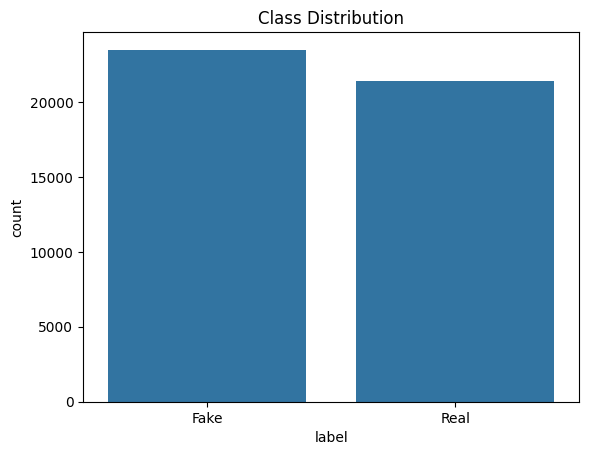

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Graph 1: Fake vs Real count
sns.countplot(x="label", data=df)
plt.xticks([0, 1], ["Fake", "Real"])
plt.title("Class Distribution")
plt.savefig("class_distribution.png")
plt.show()

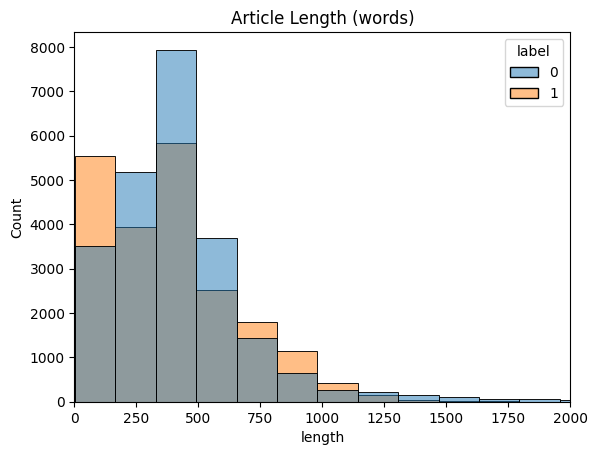

In [ ]:
# Graph 2: Text length
df["length"] = df["content"].apply(lambda x: len(x.split()))
sns.histplot(data=df, x="length", hue="label", bins=50)
plt.xlim(0, 2000)
plt.title("Article Length (words)")
plt.savefig("length_distribution.png")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["content"], df["label"], test_size=0.2, random_state=42, stratify=df["label"])

print(len(X_train), len(X_test))

35918 8980


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

tfidf = TfidfVectorizer(max_features=50000, stop_words="english")
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)

clf = LogisticRegression(max_iter=1000)
clf.fit(Xtr, y_train)

pred = clf.predict(Xte)
print(classification_report(y_test, pred, target_names=["Fake", "Real"]))

              precision    recall  f1-score   support

        Fake       0.98      0.98      0.98      4696
        Real       0.97      0.98      0.98      4284

    accuracy                           0.98      8980
   macro avg       0.98      0.98      0.98      8980
weighted avg       0.98      0.98      0.98      8980



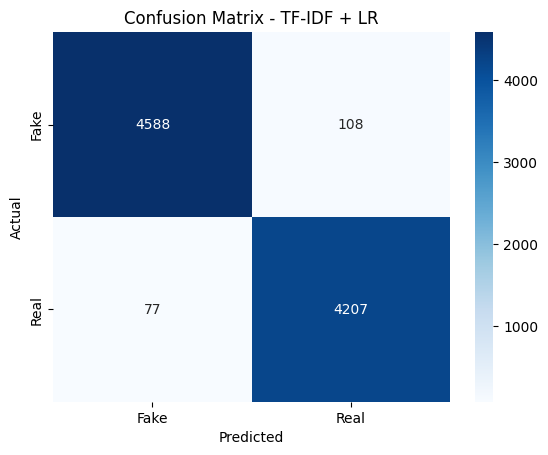

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Fake", "Real"], yticklabels=["Fake", "Real"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - TF-IDF + LR")
plt.savefig("cm_baseline.png")
plt.show()

In [ ]:
import torch
print(torch.cuda.is_available())

True


In [ ]:
from datasets import Dataset
from transformers import AutoTokenizer

train_df = pd.DataFrame({"text": X_train.values, "label": y_train.values}).sample(12000, random_state=42).reset_index(drop=True)
test_df = pd.DataFrame({"text": X_test.values, "label": y_test.values}).reset_index(drop=True)

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def tok(batch):
    return tokenizer(batch["text"], truncation=True, max_length=256)

train_ds = Dataset.from_pandas(train_df).map(tok, batched=True)
test_ds = Dataset.from_pandas(test_df).map(tok, batched=True)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/8980 [00:00<?, ? examples/s]

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from transformers import (AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding)

model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)

def metrics(p):
    preds = np.argmax(p.predictions, axis=1)
    return {"accuracy": accuracy_score(p.label_ids, preds), "f1": f1_score(p.label_ids, preds)}

args = TrainingArguments(
    output_dir="out", num_train_epochs=2,
    per_device_train_batch_size=16, per_device_eval_batch_size=64,
    learning_rate=2e-5, eval_strategy="epoch", save_strategy="no",
    fp16=True, report_to="none")

trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=test_ds,
                  data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=metrics)

trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.081675,0.016469,0.996771,0.996617
2,0.004588,0.011524,0.997773,0.997667


TrainOutput(global_step=1500, training_loss=0.03381717236836751, metrics={'train_runtime': 205.653, 'train_samples_per_second': 116.701, 'train_steps_per_second': 7.294, 'total_flos': 1589608783872000.0, 'train_loss': 0.03381717236836751, 'epoch': 2.0})

In [ ]:
save_path = "/content/drive/MyDrive/FakeNewsProject/distilbert_model"
trainer.save_model(save_path)
tokenizer.save_pretrained(save_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/FakeNewsProject/distilbert_model/tokenizer_config.json',
 '/content/drive/MyDrive/FakeNewsProject/distilbert_model/tokenizer.json')

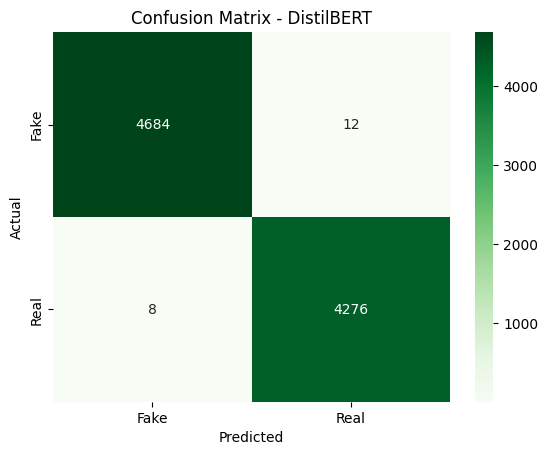

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

out = trainer.predict(test_ds)
bert_pred = np.argmax(out.predictions, axis=1)

cm = confusion_matrix(y_test, bert_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Fake", "Real"], yticklabels=["Fake", "Real"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - DistilBERT")
plt.savefig("cm_distilbert.png")
plt.show()

In [ ]:
import torch

def predict(text):
    inputs = tokenizer(text, truncation=True, max_length=256, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = torch.softmax(model(**inputs).logits, dim=1)[0]
    label = "Real" if probs[1] > probs[0] else "Fake"
    return label, float(probs.max())

# Demo ke liye 3 fake aur 3 real sample (inhe copy karke app me daalna)
samples = test_df.groupby("label").head(3)
for _, row in samples.iterrows():
    print("ACTUAL:", "Real" if row["label"] == 1 else "Fake")
    print("PREDICTED:", predict(row["text"]))
    print(row["text"][:400], "\n" + "-" * 60)

ACTUAL: Real
PREDICTED: ('Real', 0.9998051524162292)
Philippines doctor linked to New York attack plot a 'regular, generous guy' A Filipino accused by the United States of being an Islamic State supporter involved in a foiled plot to mount gun and bomb attacks in the heart of New York City is a hospital doctor described by colleagues as a  kind and generous guy . U.S. prosecutors said on Friday they had charged 37-year-old Russell Salic with terrori 
------------------------------------------------------------
ACTUAL: Real
PREDICTED: ('Real', 0.9998300075531006)
More Republicans expect Clinton, rather than Trump, to win U.S. election More Republicans now think Democrat Hillary Clinton, rather than Donald Trump, will win the presidency, as their party’s candidate struggles with difficulties including allegations of sexual misconduct and his suggestion he may not honor the outcome of the election. A Reuters/Ipsos poll released on Wednesday and conducted fro 
-----------------------------